# 천안시 스마트교차로 교통량 예측 및 고교통량 조기경보

9조 최종 결과 분석 노트북

이 노트북은 저장소에 보관된 실제 전처리 데이터와 평가 결과를 사용하여 다음 내용을 확인한다.

- 데이터 범위와 품질
- 시간대 및 평일·주말 교통량 패턴
- 단순 기준과 후보 회귀 모델 성능
- 고교통량 경보 성능
- Bias-Variance 진단
- SHAP 주요 영향 변수
- 최종 Random Forest 시험 결과

고교통량은 접근로별 학습 기간 교통량의 90백분위수를 초과한 상태이며, 실제 교통 정체와 같은 의미가 아니다.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

repo_root = Path.cwd()
if not (repo_root / "data").exists():
    repo_root = repo_root.parent

assert (repo_root / "data").exists(), "저장소 루트에서 실행하거나 notebooks 폴더에서 실행해야 합니다."

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 20)

print(f"저장소 경로: {repo_root}")

저장소 경로: C:\Users\ksh62\OneDrive\Desktop\공부\창문해\pROJECT\cheonan_car_traffic_prediction_and_warning_project


## 데이터 불러오기

선정된 12개 교차로와 44개 접근로의 시간당 교통량 데이터를 불러온다. 원본의 날짜별 24개 시간대 열은 전처리 단계에서 시간당 한 행의 롱 형식으로 변환되어 있다.

In [2]:
traffic_path = repo_root / "data" / "processed" / "selected_traffic_long.csv"
traffic = pd.read_csv(traffic_path, parse_dates=["timestamp", "date"])

daily = (
    traffic.groupby(["date", "intersection", "approach"], as_index=False)
    .agg(hour_count=("volume", "size"), volume_sum=("volume", "sum"))
)
daily_all_zero = daily.query("hour_count == 24 and volume_sum == 0")

summary = pd.DataFrame(
    {
        "항목": [
            "분석 시작 시각",
            "분석 종료 시각",
            "시간당 관측 행",
            "교차로 수",
            "접근로 수",
            "교통량 결측 행",
            "음수 교통량 행",
            "교통량 0인 시간당 행",
            "24시간 전체가 0인 일별 기록",
        ],
        "값": [
            traffic["timestamp"].min(),
            traffic["timestamp"].max(),
            f"{len(traffic):,}",
            traffic["intersection"].nunique(),
            traffic["approach"].nunique(),
            int(traffic["volume"].isna().sum()),
            int((traffic["volume"] < 0).sum()),
            f"{int((traffic['volume'] == 0).sum()):,}",
            f"{len(daily_all_zero):,}",
        ],
    }
)
display(summary)

,항목,값
0,분석 시작 시각,2024-01-01 00:00:00
1,분석 종료 시각,2026-08-31 23:00:00
2,시간당 관측 행,"1,028,544"
3,교차로 수,12
4,접근로 수,44
5,교통량 결측 행,0
6,음수 교통량 행,0
7,교통량 0인 시간당 행,"54,193"
8,24시간 전체가 0인 일별 기록,"1,277"


### 결과 해석

분석 데이터는 2024년 1월부터 2026년 8월까지의 시간당 관측값으로 구성된다. 교통량 결측값과 음수값은 없었다. 한두 시간의 0값은 실제 통행량이 없었던 시간대일 수 있으므로 일괄 제거하지 않았다. 하루 24시간이 모두 0인 일별 기록은 센서 작동 또는 데이터 수집 중단 가능성을 고려하여 품질 플래그를 적용한 뒤 모델 학습에서 제외하였다.

## 시간대 및 평일·주말 패턴

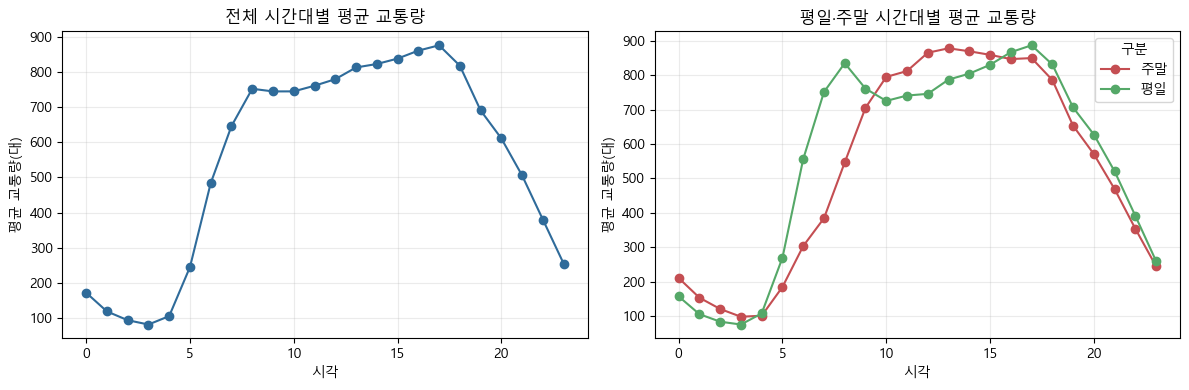

전체 평균 교통량 최고 시각: 17시
평일 최고 시각: 17시
주말 최고 시각: 13시


In [3]:
hourly_mean = traffic.groupby("hour")["volume"].mean()
day_type_mean = (
    traffic.assign(구분=traffic["is_weekend"].map({False: "평일", True: "주말"}))
    .groupby(["hour", "구분"])["volume"]
    .mean()
    .unstack()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hourly_mean.plot(ax=axes[0], marker="o", color="#2F6B9A")
axes[0].set_title("전체 시간대별 평균 교통량")
axes[0].set_xlabel("시각")
axes[0].set_ylabel("평균 교통량(대)")
axes[0].grid(alpha=0.25)

day_type_mean.plot(ax=axes[1], marker="o", color=["#C44E52", "#55A868"])
axes[1].set_title("평일·주말 시간대별 평균 교통량")
axes[1].set_xlabel("시각")
axes[1].set_ylabel("평균 교통량(대)")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"전체 평균 교통량 최고 시각: {int(hourly_mean.idxmax())}시")
print(f"평일 최고 시각: {int(day_type_mean['평일'].idxmax())}시")
print(f"주말 최고 시각: {int(day_type_mean['주말'].idxmax())}시")

### 결과 해석

교통량은 시간대와 요일에 따라 반복되는 패턴을 보인다. 평일에는 퇴근 시간대, 주말에는 낮 시간대의 평균 교통량이 상대적으로 높다. 따라서 시간·요일과 직전 시간·전날·전주 교통량은 1시간 후 교통량 예측에 필요한 주요 입력 변수이다.

## 회귀 모델 성능 비교

,모델,MAE(대),WAPE(%),RMSE(대)
0,Random Forest,36.00,6.15,77.73
1,XGBoost,37.70,6.44,77.59
2,CatBoost,39.97,6.83,79.31
3,HistGradientBoosting,40.78,6.96,81.07
4,Ridge(alpha=1),62.43,10.66,111.58
5,전주 같은 시간,80.31,13.71,215.00
6,전날 같은 시간,89.65,15.31,199.79
7,지속성,100.28,17.12,172.74


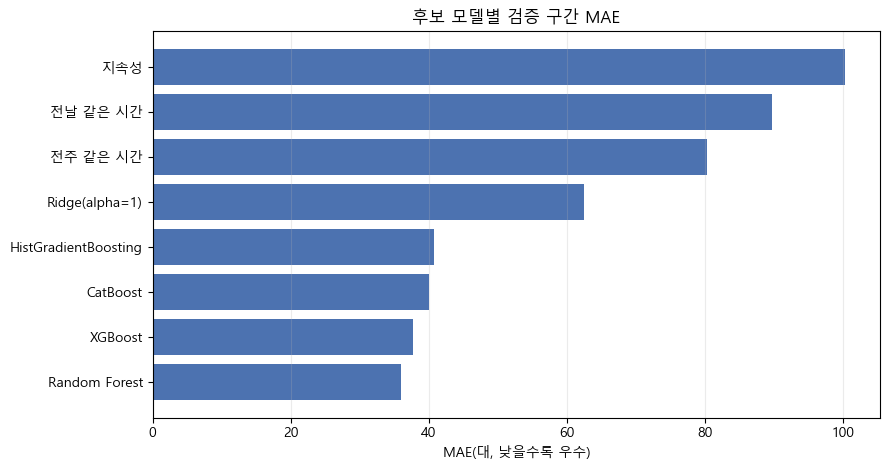

In [4]:
evaluation_dir = repo_root / "data" / "processed" / "evaluation"
regression = pd.read_csv(evaluation_dir / "extended_model_comparison.csv")
regression_table = regression[["label", "mae", "wape", "rmse"]].copy()
regression_table.columns = ["모델", "MAE(대)", "WAPE(%)", "RMSE(대)"]
regression_table["WAPE(%)"] *= 100
display(regression_table.round(2))

plot_data = regression_table.sort_values("MAE(대)", ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(plot_data["모델"], plot_data["MAE(대)"], color="#4C72B0")
ax.set_title("후보 모델별 검증 구간 MAE")
ax.set_xlabel("MAE(대, 낮을수록 우수)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 결과 해석

Random Forest는 검증 구간에서 MAE 36.00대와 WAPE 6.15%로 가장 안정적인 성능을 보였다. XGBoost의 RMSE는 Random Forest보다 소폭 낮았지만 MAE와 WAPE는 Random Forest가 더 낮았다. XGBoost와 CatBoost 비교는 최종 시험 결과 확인 이후의 보충 실험이며, 보관한 시험 데이터를 이용해 최종 모델을 다시 선정하지 않았다.

## 고교통량 경보 성능

,모델,Precision,Recall,F1,PR-AUC
0,Random Forest,0.831,0.721,0.772,0.847
1,XGBoost,0.804,0.732,0.766,0.831
2,HistGradientBoosting,0.815,0.680,0.742,0.815
3,CatBoost,0.772,0.713,0.741,0.807


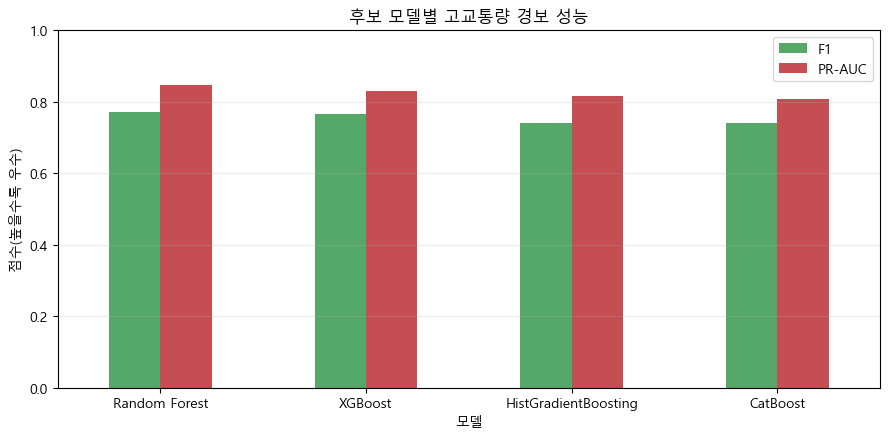

In [5]:
alerts = pd.read_csv(evaluation_dir / "extended_alert_comparison.csv")
alert_table = alerts[["model", "precision", "recall", "f1", "pr_auc"]].copy()
name_map = {
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
    "hist_gradient_boosting": "HistGradientBoosting",
    "catboost": "CatBoost",
}
alert_table["model"] = alert_table["model"].map(name_map)
alert_table.columns = ["모델", "Precision", "Recall", "F1", "PR-AUC"]
display(alert_table.round(3))

ax = alert_table.set_index("모델")[["F1", "PR-AUC"]].plot(
    kind="bar", figsize=(9, 4.5), color=["#55A868", "#C44E52"]
)
ax.set_title("후보 모델별 고교통량 경보 성능")
ax.set_ylabel("점수(높을수록 우수)")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 결과 해석

Random Forest는 Precision 0.831, Recall 0.721, F1 0.772, PR-AUC 0.847을 기록하였다. XGBoost는 Recall이 더 높았지만 Precision, F1과 PR-AUC는 Random Forest가 더 높았다. 불필요한 경보와 놓친 고교통량 사이의 균형을 고려하여 Random Forest를 최종 모델로 확정하였다.

## Bias-Variance 진단

,max_depth,train_rows,validation_rows,train_mae,validation_mae,mae_gap,validation_wape,validation_rmse
0,6,20000,30000,59.97,54.09,-5.89,0.09,103.73
1,6,60000,30000,61.14,53.37,-7.77,0.09,101.08
2,6,120000,30000,61.56,53.31,-8.25,0.09,99.79
3,12,20000,30000,43.67,44.92,1.25,0.08,93.20
4,12,60000,30000,42.88,41.91,-0.97,0.07,89.52
5,12,120000,30000,42.53,40.59,-1.94,0.07,86.29
6,18,20000,30000,42.50,44.48,1.98,0.08,94.04
7,18,60000,30000,39.18,41.36,2.18,0.07,88.80
8,18,120000,30000,37.73,39.34,1.61,0.07,84.40


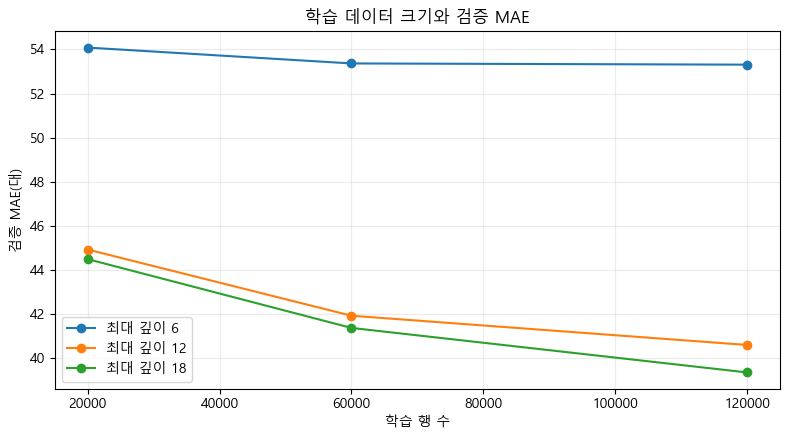

In [6]:
bias_variance = pd.read_csv(evaluation_dir / "bias_variance_metrics.csv")
display(bias_variance.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
for depth, group in bias_variance.groupby("max_depth"):
    ax.plot(group["train_rows"], group["validation_mae"], marker="o", label=f"최대 깊이 {depth}")
ax.set_title("학습 데이터 크기와 검증 MAE")
ax.set_xlabel("학습 행 수")
ax.set_ylabel("검증 MAE(대)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 결과 해석

최대 깊이 6에서는 학습·검증 오차가 모두 높아 충분히 복잡한 패턴을 학습하지 못하는 경향이 나타났다. 깊이 12와 18에서는 학습 데이터가 늘어날수록 검증 MAE가 감소하였다. 깊이 18, 학습 120,000행 조건에서 학습 MAE와 검증 MAE의 차이는 약 1.61대로, 심각한 과적합보다 충분한 학습 데이터 확보가 중요하다고 해석할 수 있다.

## SHAP 주요 영향 변수

,feature_label,mean_abs_shap,비중(%)
0,1시간 전 교통량,310.69,56.00
1,전날 같은 시각 교통량,91.51,16.49
2,전주 같은 시각 교통량,63.81,11.50
3,예측 시각(cos),21.29,3.84
4,예측 시각(sin),19.82,3.57
5,최근 3시간 평균,18.55,3.34
6,2시간 전 교통량,7.01,1.26
7,최근 6시간 변동성,5.31,0.96
8,3시간 전 교통량,3.61,0.65
9,최근 6시간 평균,2.65,0.48


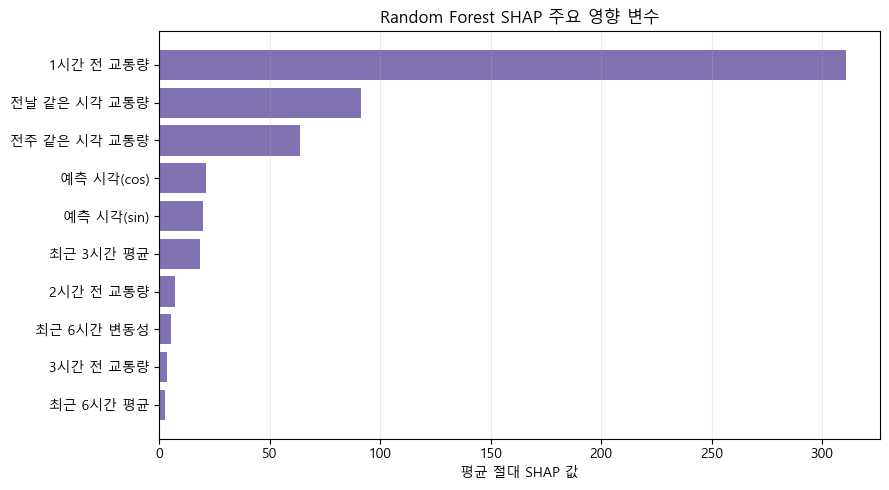

In [7]:
shap_importance = pd.read_csv(evaluation_dir / "shap_feature_importance.csv")
shap_top = shap_importance.head(10).copy()
shap_top["비중(%)"] = shap_top["importance_share"] * 100
display(shap_top[["feature_label", "mean_abs_shap", "비중(%)"]].round(2))

plot_data = shap_top.sort_values("mean_abs_shap", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data["feature_label"], plot_data["mean_abs_shap"], color="#8172B2")
ax.set_title("Random Forest SHAP 주요 영향 변수")
ax.set_xlabel("평균 절대 SHAP 값")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 결과 해석

1시간 전 교통량의 SHAP 비중이 가장 높았고, 전날 같은 시각과 전주 같은 시각의 교통량이 뒤를 이었다. 이는 최종 Random Forest가 최근 교통 흐름과 하루·일주일 주기의 반복 패턴을 주요 입력 변수로 활용했음을 의미한다. SHAP은 모델 내부의 예측 기여도를 설명하며 실제 인과관계를 증명하지 않는다.

## 최종 시험 결과

In [8]:
final_config = json.loads((repo_root / "config" / "final_model.json").read_text(encoding="utf-8"))
validation = final_config["validation_metrics"]
test = final_config["test_metrics"]

final_table = pd.DataFrame(
    [
        ["검증 데이터", validation["mae"], validation["wape"] * 100, validation["rmse"], validation["precision"], validation["recall"], validation["f1"], validation["pr_auc"]],
        ["시험 데이터", test["mae"], test["wape"] * 100, test["rmse"], test["precision"], test["recall"], test["f1"], test["pr_auc"]],
    ],
    columns=["구간", "MAE(대)", "WAPE(%)", "RMSE(대)", "Precision", "Recall", "F1", "PR-AUC"],
)
display(final_table.round(3))
print(f"최종 재학습 행 수: {final_config['training_rows']:,}")
print(f"보관 시험 행 수: {final_config['test_rows']:,}")

,구간,MAE(대),WAPE(%),RMSE(대),Precision,Recall,F1,PR-AUC
0,검증 데이터,35.995,6.147,77.732,0.831,0.721,0.772,0.847
1,시험 데이터,31.458,5.209,55.275,0.840,0.727,0.780,0.860


최종 재학습 행 수: 895,560
보관 시험 행 수: 94,944


### 최종 해석

학습 데이터와 검증 데이터를 합쳐 다시 학습한 최종 Random Forest는 보관된 시험 데이터에서 MAE 31.46대, WAPE 5.21%, RMSE 55.27대를 기록하였다. 고교통량 경보 성능은 Precision 0.840, Recall 0.727, F1 0.780, PR-AUC 0.860이었다. 시험 결과를 확인한 이후 모델 설정을 변경하거나 시험 데이터에 맞춰 재학습하지 않았다.

로컬 서비스는 사용자가 교차로와 접근로를 선택하면 저장된 마지막 관측 시각의 1시간 후 교통량과 고교통량 위험을 제공한다. 이 결과는 실제 정체 확정이나 직접적인 교통 통제 판단이 아니라 추가 확인이 필요한 고교통량 위험 신호로 해석해야 한다.